[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shuishen112/neural-networks/blob/main/language_models/01_bigram.ipynb)

# LM 1 — Bigram Language Models: Counting and Softmax Regression

*Companion to Lecture 1 — Linear Models and the Perceptron.*

A large language model is, at heart, a machine that assigns a probability to the
next token given the previous ones. In this notebook we build the simplest possible
such machine — a **character-level bigram model** that predicts the next letter of a
name from the current letter only — first by counting, then as exactly the
**softmax regression** of Lecture 1. Along the way we meet the vocabulary that the
rest of the track (and every LLM paper) uses: tokens, the chain rule of probability,
negative log-likelihood, perplexity, smoothing and sampling.

> **Language-model track:** **1 Bigram** · 2 MLP LM · 3 Training dynamics · 4 PyTorch · 5 Word-level & regularisation · 6 WaveNet · 7 Char-RNN · 8 GPT · 9 Sequence VAE · 10 Diffusion LM

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (5, 4)
plt.rcParams["axes.grid"] = True

In [2]:
from pathlib import Path
import urllib.request

def load_text(name):
    """Load a corpus from ../data (repository checkout) or download it (e.g. on Colab)."""
    for folder in (Path("data"), Path("../data")):
        if (folder / name).exists():
            return (folder / name).read_text(encoding="utf-8")
    url = f"https://raw.githubusercontent.com/shuishen112/neural-networks/main/data/{name}"
    return urllib.request.urlopen(url).read().decode("utf-8")

## 1. What is a language model?

A **language model** is a probability distribution over sequences of tokens
$x_1, x_2, \dots, x_T$ drawn from a finite vocabulary $\mathcal V$. Any joint
distribution can be factorised exactly with the **chain rule of probability**:

$$
p(x_1, \dots, x_T) = p(x_1)\,p(x_2\mid x_1)\,p(x_3\mid x_1, x_2)\cdots
= \prod_{t=1}^{T} p(x_t \mid x_{<t}).
$$

This **autoregressive factorisation** turns the impossible task of modelling whole
sequences into a sequence of *classification* problems: given the prefix $x_{<t}$,
predict a distribution over the $|\mathcal V|$ possible next tokens. Every model in
this track — and GPT-4, Llama and Claude — has this form; they differ only in *how*
they compute $p(x_t\mid x_{<t})$.

To know where a sequence starts and stops, we add a special token. We use `.`
both as the start marker $x_0$ and as the end-of-sequence token, so the name *emma*
becomes `. e m m a .` and

$$ p(\text{emma}) = p(e\mid .)\,p(m\mid .\,e)\,p(m\mid .\,e\,m)\,p(a\mid .\,e\,m\,m)\,p(.\mid .\,e\,m\,m\,a). $$

The end token is important: without it the model could not express that names have a length.

The simplest non-trivial assumption is the **Markov** (bigram) assumption: the next
token depends only on the current one,

$$ p(x_t\mid x_{<t}) \approx p(x_t\mid x_{t-1}) . $$

An $n$-gram model conditions on the last $n-1$ tokens; we start with $n=2$.

## 2. Tokenisation in brief

Before we can model "text" we must decide what a token is. The three common choices:

* **characters** — tiny vocabulary, no unknown words, but long sequences and each
  token carries little meaning;
* **words** — short sequences and meaningful tokens, but a huge vocabulary, and any
  word not seen in training is "unknown";
* **subwords** (byte-pair encoding, WordPiece, SentencePiece) — the compromise used by
  all modern LLMs: frequent words are single tokens, rare words are split into pieces.
  We build a BPE tokeniser ourselves in LM 8.

Let us look at a line of Shakespeare and at the vocabulary sizes over the whole corpus.

In [3]:
shakespeare = load_text("tinyshakespeare.txt")
line = "Before we proceed any further, hear me speak."
print("characters:", list(line)[:20], "...")
print("words     :", line.split())

char_vocab = sorted(set(shakespeare))
word_vocab = set(shakespeare.split())
print(f"\ncorpus: {len(shakespeare):,} characters, {len(shakespeare.split()):,} words")
print(f"character vocabulary: {len(char_vocab):>6,} tokens")
print(f"word vocabulary     : {len(word_vocab):>6,} tokens (whitespace split, case and punctuation kept)")

characters: ['B', 'e', 'f', 'o', 'r', 'e', ' ', 'w', 'e', ' ', 'p', 'r', 'o', 'c', 'e', 'e', 'd', ' ', 'a', 'n'] ...
words     : ['Before', 'we', 'proceed', 'any', 'further,', 'hear', 'me', 'speak.']

corpus: 1,115,394 characters, 202,651 words
character vocabulary:     65 tokens
word vocabulary     : 25,670 tokens (whitespace split, case and punctuation kept)


Sixty-five characters versus tens of thousands of "words" (and `speak.` and `speak`
count as different words with this naive split). A word-level model needs an output
layer with one row per word, and any unseen word breaks it. For our first models we
use **characters on a dataset of names**, so the vocabulary is tiny and every
probability table fits on the screen.

## 3. The data: 32 000 names

`names.txt` holds one lower-case first name per line. We shuffle with a fixed seed and
split 80 % / 10 % / 10 % into train / validation / test (the same split is used in
every names notebook of the track, so numbers can be compared).

In [4]:
words = load_text("names.txt").split()
random.Random(42).shuffle(words)
n1, n2 = int(0.8 * len(words)), int(0.9 * len(words))
train_words, val_words, test_words = words[:n1], words[n1:n2], words[n2:]
print(f"{len(words)} names -> train {len(train_words)}, val {len(val_words)}, test {len(test_words)}")
print("examples:", train_words[:8])
print(f"length: min {min(map(len, words))}, max {max(map(len, words))}, mean {np.mean([len(w) for w in words]):.2f}")

chars = "." + "abcdefghijklmnopqrstuvwxyz"   # '.' = start/end token, index 0
stoi = {c: i for i, c in enumerate(chars)}
itos = {i: c for c, i in stoi.items()}
V = len(chars)
print("vocabulary size V =", V)

32033 names -> train 25626, val 3203, test 3204
examples: ['yuheng', 'diondre', 'xavien', 'jori', 'juanluis', 'erandi', 'phia', 'samatha']
length: min 2, max 15, mean 6.12
vocabulary size V = 27


Each name of length $L$ contributes $L+1$ bigrams $(x_{t-1}, x_t)$, from `(., first letter)` to
`(last letter, .)`. We store them as two integer arrays: inputs `xs` and targets `ys`.

In [5]:
def bigrams(word_list):
    xs, ys = [], []
    for w in word_list:
        s = "." + w + "."
        for a, b in zip(s, s[1:]):
            xs.append(stoi[a]); ys.append(stoi[b])
    return np.array(xs), np.array(ys)

x_tr, y_tr = bigrams(train_words)
x_va, y_va = bigrams(val_words)
print(f"{len(x_tr):,} training bigrams, {len(x_va):,} validation bigrams")
L0 = len(train_words[0]) + 1
print(f"'{train_words[0]}' as bigrams:", [itos[a] + itos[b] for a, b in zip(x_tr[:L0], y_tr[:L0])])

182,625 training bigrams, 22,655 validation bigrams
'yuheng' as bigrams: ['.y', 'yu', 'uh', 'he', 'en', 'ng', 'g.']


## 4. The bigram model by counting

The maximum-likelihood estimate of a categorical distribution is the empirical
frequency. Let $N_{ij}$ be the number of times character $j$ follows character $i$ in
the training set. Then

$$ \hat p(x_t = j \mid x_{t-1} = i) = \frac{N_{ij}}{\sum_k N_{ik}} . $$

(Exercise: derive this by maximising $\sum_{ij}N_{ij}\log p_{ij}$ subject to
$\sum_j p_{ij} = 1$ with a Lagrange multiplier.) The whole model is a $27\times27$ table.
`np.add.at` increments `N[x, y]` once for every pair, also when the same pair occurs
many times (plain fancy-index assignment `N[xs, ys] += 1` would count duplicates only once).

total bigrams: 182625 | distinct bigrams seen: 620 of 729


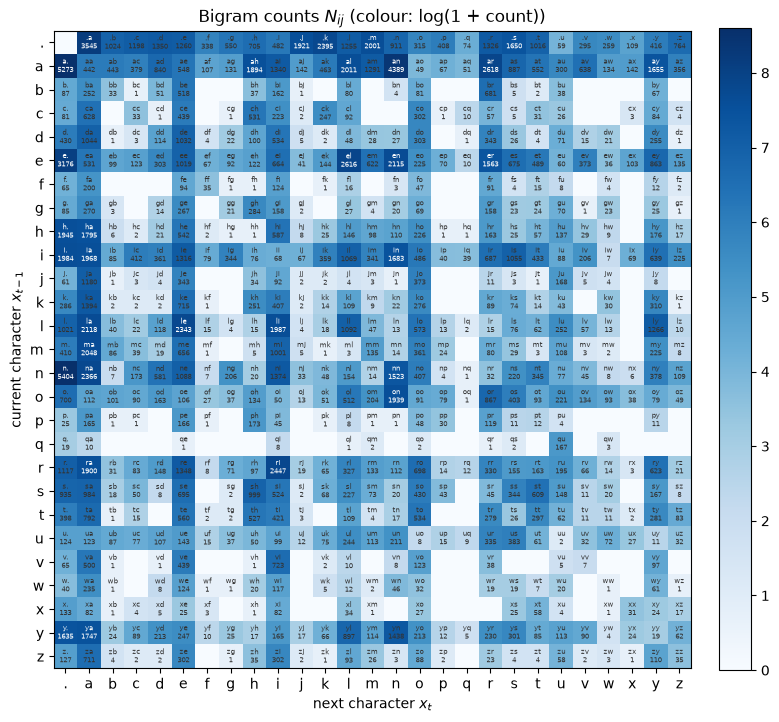

In [6]:
N = np.zeros((V, V))
np.add.at(N, (x_tr, y_tr), 1)
print("total bigrams:", int(N.sum()), "| distinct bigrams seen:", int((N > 0).sum()), "of", V * V)

fig, ax = plt.subplots(figsize=(9, 9))
im = ax.imshow(np.log1p(N), cmap="Blues")
for i in range(V):
    for j in range(V):
        if N[i, j] > 0:
            ax.text(j, i, f"{itos[i]}{itos[j]}\n{int(N[i, j])}", ha="center", va="center",
                    fontsize=5, color="white" if N[i, j] > 1500 else "0.2")
ax.set_xticks(range(V)); ax.set_xticklabels(list(chars))
ax.set_yticks(range(V)); ax.set_yticklabels(list(chars))
ax.set_xlabel("next character $x_t$"); ax.set_ylabel("current character $x_{t-1}$")
ax.grid(False); ax.set_title("Bigram counts $N_{ij}$ (colour: log(1 + count))")
plt.colorbar(im, fraction=0.046, pad=0.04); plt.show()

A few things to read off the table:

* Row `.` is the distribution of **first letters** (lots of `a`, `k`, `m`, `j`, few `u`, `q`, `x`).
* Column `.` is the distribution of **last letters**: names end in `n`, `a`, `e`, `i` and `h` most often.
* The entry `(., .)` is zero: there are no empty names.
* Many cells are zero, such as `qz` or `jx`. Some are impossible in English names, but some are
  just *rare* — and that is a problem, as we will see.

Normalising every row gives the conditional distributions $\hat p(\cdot\mid i)$.

In [7]:
P_mle = N / N.sum(axis=1, keepdims=True)
def top(row, k):
    return ", ".join(f"{chars[j]}: {row[j]:.3f}" for j in np.argsort(-row)[:k])

print("p(next | '.') top 5 :", top(P_mle[0], 5))
print("most common last letters (column '.'):", ", ".join(f"{chars[i]} ({int(N[i, 0])})" for i in np.argsort(-N[:, 0])[:5]))
print("p(next | 'q') top 3 :", top(P_mle[stoi['q']], 3))
print("rows sum to one:", np.allclose(P_mle.sum(axis=1), 1))

p(next | '.') top 5 : a: 0.138, k: 0.093, m: 0.078, j: 0.075, s: 0.064
most common last letters (column '.'): n (5404), a (5273), e (3176), i (1984), h (1945)
p(next | 'q') top 3 : u: 0.773, .: 0.088, a: 0.046
rows sum to one: True


## 5. Evaluating a language model: NLL and perplexity

How good is a model $p_\theta$? The natural score is the **likelihood** it assigns to
held-out text. Because products of many small probabilities underflow, we use the
average **negative log-likelihood** per token,

$$
\text{NLL} = -\frac{1}{T}\sum_{t=1}^{T}\log p_\theta(x_t\mid x_{<t}) ,
$$

measured in **nats** (natural log; divide by $\ln 2$ for bits). This is exactly the
**cross-entropy loss** of Lecture 1, averaged over all next-token predictions — so the
training loss of an LLM *is* its NLL on the training data. Lower is better.

**Perplexity** is $\text{PPL} = e^{\text{NLL}}$. It has a neat interpretation: a model
with perplexity $k$ is as uncertain, on average, as if it had to choose uniformly
among $k$ tokens at every step. The **uniform baseline** assigns $1/27$ to every
character, so $\text{NLL} = \ln 27 \approx 3.30$ and $\text{PPL} = 27$. Any model worth
having must beat this.

In [8]:
def nll(P, xs, ys):
    """Mean negative log-likelihood (nats/char) of a bigram table P on pairs (xs, ys)."""
    with np.errstate(divide="ignore"):
        return -np.mean(np.log(P[xs, ys]))

print(f"uniform baseline: NLL = ln 27 = {np.log(V):.3f}, PPL = {V}")
print(f"MLE bigram, train: NLL = {nll(P_mle, x_tr, y_tr):.4f}, PPL = {np.exp(nll(P_mle, x_tr, y_tr)):.2f}")
print(f"MLE bigram, val  : NLL = {nll(P_mle, x_va, y_va):.4f}")

unseen = N[x_va, y_va] == 0
print(f"validation bigrams never seen in training: {unseen.sum()}  e.g.",
      sorted({itos[a] + itos[b] for a, b in zip(x_va[unseen], y_va[unseen])})[:10])

uniform baseline: NLL = ln 27 = 3.296, PPL = 27
MLE bigram, train: NLL = 2.4541, PPL = 11.64
MLE bigram, val  : NLL = inf
validation bigrams never seen in training: 5  e.g. ['gf', 'jp', 'kv', 'pj', 'sf']


On the training data the bigram model has perplexity ≈ 11.6 — it has narrowed 27
choices down to about 12. On the validation data the NLL is **infinite**: a handful of
validation bigrams never occurred in training, the MLE assigns them probability
exactly $0$, and $-\log 0 = \infty$. A single unseen pair makes the whole validation
set "impossible". This is the classic **zero-probability problem** of $n$-gram models,
and it gets much worse as $n$ grows (LM 2).

## 6. Smoothing

The simplest fix is **add-$\alpha$ (Laplace / Lidstone) smoothing**: pretend we have seen
every bigram $\alpha$ extra times,

$$ \hat p_\alpha(j\mid i) = \frac{N_{ij} + \alpha}{\sum_k N_{ik} + V\alpha} . $$

$\alpha = 0$ is the MLE; $\alpha\to\infty$ is the uniform model. It is the posterior mean
under a symmetric Dirichlet($\alpha$) prior — our first example of a *prior* acting as a
*regulariser*. We choose $\alpha$ on the validation set. To see the effect clearly we
also repeat the experiment pretending we only had **200 training names**, where
overfitting is severe.

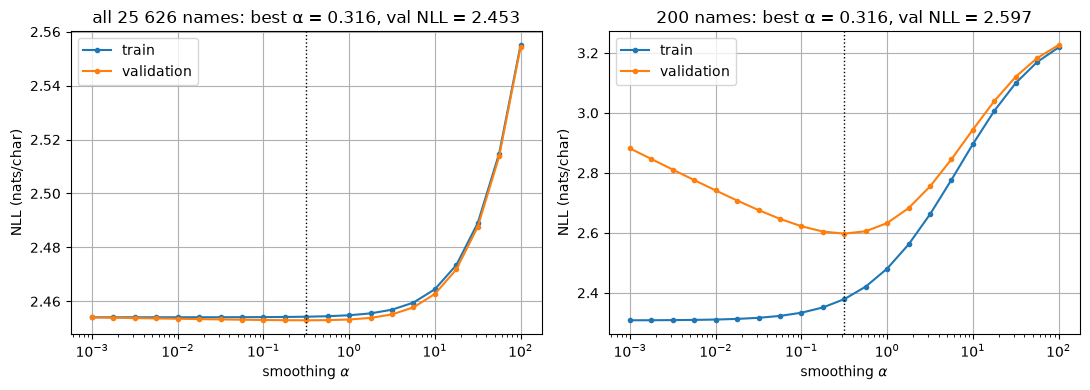

In [9]:
def bigram_table(xs, ys, alpha):
    C = np.zeros((V, V)); np.add.at(C, (xs, ys), 1)
    return (C + alpha) / (C + alpha).sum(axis=1, keepdims=True)

alphas = np.logspace(-3, 2, 21)
x_small, y_small = bigrams(train_words[:200])
res = {}
for label, (xs, ys) in {"all 25 626 names": (x_tr, y_tr), "200 names": (x_small, y_small)}.items():
    res[label] = [(nll(bigram_table(xs, ys, a), xs, ys), nll(bigram_table(xs, ys, a), x_va, y_va)) for a in alphas]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (label, r) in zip(axes, res.items()):
    r = np.array(r)
    ax.semilogx(alphas, r[:, 0], "o-", ms=3, label="train")
    ax.semilogx(alphas, r[:, 1], "o-", ms=3, label="validation")
    best = alphas[np.argmin(r[:, 1])]
    ax.axvline(best, color="k", ls=":", lw=1)
    ax.set_title(f"{label}: best α = {best:.3g}, val NLL = {r[:, 1].min():.3f}")
    ax.set_xlabel(r"smoothing $\alpha$"); ax.set_ylabel("NLL (nats/char)"); ax.legend()
plt.tight_layout(); plt.show()

* With the full training set, any small $\alpha$ removes the infinities and the curve is
  flat over several orders of magnitude: 25 000 names are plenty of data for 729
  parameters. Too much smoothing (large $\alpha$) pulls the model towards uniform and both
  losses go up — **underfitting**.
* With 200 names the picture is the textbook one: training loss increases monotonically
  with $\alpha$, validation loss is U-shaped. The gap between the curves is
  **overfitting**, and $\alpha$ trades bias against variance.

We keep the best $\alpha$ for the full data as our count-based bigram model.

In [10]:
alpha_best = alphas[np.argmin(np.array(res["all 25 626 names"])[:, 1])]
P_bigram = bigram_table(x_tr, y_tr, alpha_best)
nll_count_val = nll(P_bigram, x_va, y_va)
print(f"add-alpha bigram (alpha = {alpha_best:.3g}): train NLL {nll(P_bigram, x_tr, y_tr):.4f}, "
      f"val NLL {nll_count_val:.4f}, val PPL {np.exp(nll_count_val):.2f}")

add-alpha bigram (alpha = 0.316): train NLL 2.4543, val NLL 2.4530, val PPL 11.62


## 7. Sampling names

A language model is also a **generator**. Because of the autoregressive factorisation
we sample one token at a time: start from `.`, draw $x_1\sim p(\cdot\mid .)$, then
$x_2\sim p(\cdot\mid x_1)$, …, until we draw `.` again. This is *exactly* how an LLM
writes text (with a far better $p$).

In [11]:
def sample_bigram(P, n, seed=0):
    r = np.random.default_rng(seed)
    out = []
    for _ in range(n):
        ix, name = 0, ""
        while True:
            ix = r.choice(V, p=P[ix])
            if ix == 0:
                break
            name += itos[ix]
        out.append(name)
    return out

print("bigram  :", ", ".join(sample_bigram(P_bigram, 15)))
print("uniform :", ", ".join(sample_bigram(np.full((V, V), 1 / V), 8)))

bigram  : ma, aruorixt, s, n, sh, ja, minazynena, nahauveman, itan, spet, faloi, ia, len, wdanshumanzydmelmarjubruw, sytayron
uniform : qga, uxpsnyv, w, sdwnhk, crqpjzzrqrjcsnhmxyiohpijxfpbvufwaidlufajebohreyibpykymkpzyltmnukssycsyz, wzydzxvlfuxgnkyasp, s, tmyavaikzoffwfcgonuogkvpyinpvcjxavkv


The bigram samples have the right "texture" — plausible letter pairs, sensible first
and last letters — but no memory: once the model is at `n` it has forgotten
everything before it, so names are often too short, too long, or unpronounceable. The
uniform model produces random strings of geometric length (mean 26 characters). More
context will help; that is LM 2.

## 8. The same model as softmax regression

Now we forget counting and *learn* the bigram model with gradient descent. Encode the
current character as a **one-hot** vector $\mathbf x\in\{0,1\}^{27}$ and use the softmax
regression of Lecture 1 (no bias needed, see below):

$$ \mathbf z = W^\top\mathbf x, \qquad p(x_t = j\mid x_{t-1}) = \operatorname{softmax}(\mathbf z)_j, \qquad W\in\mathbb R^{27\times27}. $$

Since $\mathbf x$ is one-hot with a $1$ at position $i$, the product $W^\top\mathbf x$ simply
**selects row $i$ of $W$**. So $W$ is a **table of logits**: row $i$ holds the
unnormalised log-probabilities of the next character after $i$, and
$\exp(W_{ij})$ plays the role of the count $N_{ij}$ (up to a per-row constant). A bias
$\mathbf b$ would just add the same vector to every row, so it is redundant here.

The loss is the mean cross-entropy over the training bigrams — the NLL of Section 5 —
and Lecture 1 gave us its gradient, "prediction minus target":

$$ \mathcal L(W) = -\frac1n\sum_{m=1}^{n}\log\operatorname{softmax}(W^\top\mathbf x_m)_{y_m}, \qquad
   \nabla_W\mathcal L = \frac1n X^\top(P - Y). $$

Let us check the two claims in code: the one-hot matrix product equals a row lookup,
and the gradient matches.

In [12]:
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)   # shift for numerical stability (Lecture 1)
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

def one_hot(y, K):
    Y = np.zeros((len(y), K)); Y[np.arange(len(y)), y] = 1; return Y

W = rng.normal(size=(V, V))
X, Y = one_hot(x_tr, V), one_hot(y_tr, V)       # (n, 27) each
print("X @ W == W[x_tr]  :", np.allclose(X @ W, W[x_tr]))
P = softmax(X @ W)
grad_onehot = X.T @ (P - Y) / len(X)            # Lecture 1's formula, literally

X @ W == W[x_tr]  : True


Multiplying a $182\,000\times27$ one-hot matrix is wasteful. Group the sum by the
input character: all examples with $x_m = i$ share the same prediction
$\mathbf p_i = \operatorname{softmax}(W_{i,:})$, there are $r_i = \sum_j N_{ij}$ of them, and
$N_{ij}$ of them have target $j$. Hence

$$
\mathcal L(W) = -\frac1n\sum_{i,j} N_{ij}\log \operatorname{softmax}(W_{i,:})_j, \qquad
\nabla_{W_{i,:}}\mathcal L = \frac1n\big(r_i\,\mathbf p_i - N_{i,:}\big).
$$

The **counts are sufficient statistics**: the learning problem only ever "sees" the
table $N$. Setting the gradient to zero gives $\mathbf p_i = N_{i,:}/r_i$ — the
minimiser of the softmax regression is *exactly* the counting model of Section 4.
Gradient descent and counting are two roads to the same place.

In [13]:
def loss_grad(W, counts, lam=0.0):
    """Full-batch cross-entropy of the bigram softmax regression (+ L2), computed from the counts."""
    n, r = counts.sum(), counts.sum(axis=1, keepdims=True)
    logP = W - W.max(axis=1, keepdims=True)
    logP = logP - np.log(np.exp(logP).sum(axis=1, keepdims=True))
    loss = -(counts * logP).sum() / n + lam * (W ** 2).sum()
    grad = (r * np.exp(logP) - counts) / n + 2 * lam * W
    return loss, grad

_, grad_counts = loss_grad(W, N)
print("max |one-hot gradient - count gradient| =", np.abs(grad_onehot - grad_counts).max())
del X, Y, P   # free ~80 MB

max |one-hot gradient - count gradient| = 7.28583859910259e-17


Now train with plain full-batch gradient descent from $W = 0$. At $W=0$ all logits are
equal, the prediction is uniform and the loss is $\ln 27$ — a useful sanity check that
we will meet again in LM 3. The gradient for row $i$ is scaled by $r_i/n$, the
frequency of character $i$, so rows for rare characters (`q`, `x`) learn slowly and
we need a large learning rate.

loss at W = 0      : 3.2958   (ln 27 = 3.2958)
after 3000 GD steps: train 2.4545, val 2.4529
count-based MLE    : train 2.4541


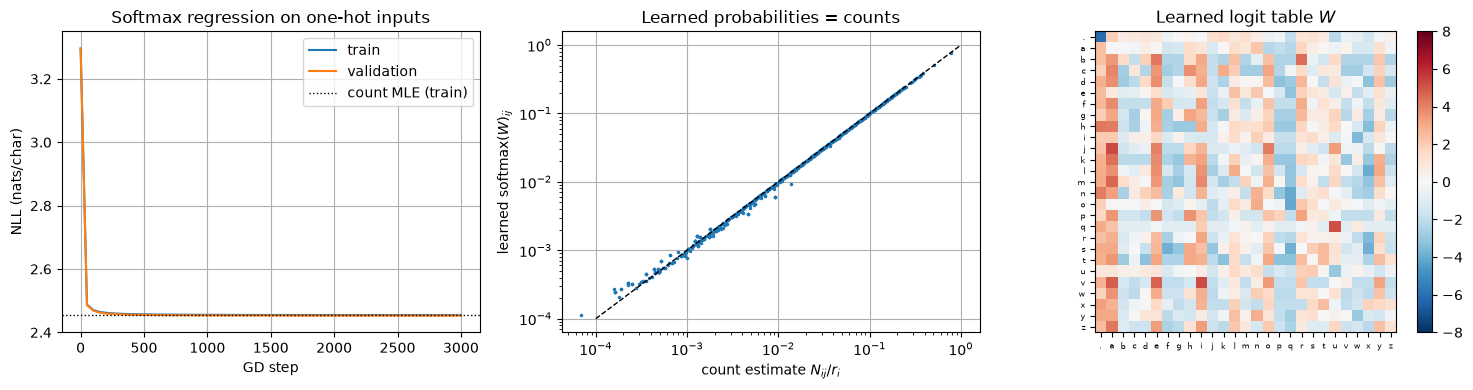

max |softmax(W) - P_mle| over all cells: 0.0045


In [14]:
def train_bigram_gd(counts, lam=0.0, lr=50.0, steps=3000, log_every=50):
    W = np.zeros((V, V))
    hist = []
    for t in range(steps + 1):
        loss, grad = loss_grad(W, counts, lam)
        if t % log_every == 0:
            P = softmax(W)
            hist.append((t, nll(P, x_tr, y_tr), nll(P, x_va, y_va)))
        W -= lr * grad
    return W, np.array(hist)

W_gd, hist = train_bigram_gd(N)
P_gd = softmax(W_gd)
print(f"loss at W = 0      : {hist[0, 1]:.4f}   (ln 27 = {np.log(V):.4f})")
print(f"after 3000 GD steps: train {hist[-1, 1]:.4f}, val {hist[-1, 2]:.4f}")
print(f"count-based MLE    : train {nll(P_mle, x_tr, y_tr):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(hist[:, 0], hist[:, 1], label="train")
axes[0].plot(hist[:, 0], hist[:, 2], label="validation")
axes[0].axhline(nll(P_mle, x_tr, y_tr), color="k", ls=":", lw=1, label="count MLE (train)")
axes[0].set_ylim(2.4, 3.35); axes[0].set_xlabel("GD step"); axes[0].set_ylabel("NLL (nats/char)")
axes[0].legend(); axes[0].set_title("Softmax regression on one-hot inputs")
axes[1].loglog(P_mle[N > 0], P_gd[N > 0], ".", ms=3)
axes[1].plot([1e-4, 1], [1e-4, 1], "k--", lw=1)
axes[1].set_xlabel(r"count estimate $N_{ij}/r_i$"); axes[1].set_ylabel(r"learned softmax$(W)_{ij}$")
axes[1].set_title("Learned probabilities = counts")
im = axes[2].imshow(W_gd, cmap="RdBu_r", vmin=-8, vmax=8)
axes[2].set_xticks(range(V)); axes[2].set_xticklabels(list(chars), fontsize=6)
axes[2].set_yticks(range(V)); axes[2].set_yticklabels(list(chars), fontsize=6)
axes[2].grid(False); axes[2].set_title("Learned logit table $W$"); plt.colorbar(im, ax=axes[2])
plt.tight_layout(); plt.show()
print("max |softmax(W) - P_mle| over all cells:", np.abs(P_gd - P_mle).max().round(4))

The loss falls from $\ln 27$ to the count-based optimum, and the learned probabilities
lie on the diagonal: the network has rediscovered the count table. The heat map of $W$
looks like the log of the count map of Section 4 — up to a constant per row, which the
softmax ignores.

Notice what happens to cells with **zero counts**: the gradient keeps pushing their
logits down, but $\log 0 = -\infty$ is never reached in finitely many steps. Gradient
descent with **early stopping** therefore smooths implicitly, and the validation NLL is
finite (compare Section 5).

## 9. L2 regularisation is smoothing

Add a weight penalty $\lambda\lVert W\rVert_2^2$ to the loss (already built into `loss_grad`, argument `lam`).
At the optimum, row $i$ satisfies

$$ \frac{r_i}{n}\,\mathbf p_i - \frac{N_{i,:}}{n} + 2\lambda W_{i,:} = 0 . $$

The penalty pulls all logits towards $0$, i.e. every row towards the **uniform**
distribution — exactly what add-$\alpha$ does to the counts. In Bayesian terms add-$\alpha$
is a Dirichlet prior on the probabilities and L2 is a Gaussian prior on the logits; both
say "unseen does not mean impossible". As with $\alpha$, the effect is strongest for rows
with few observations (small $r_i$), because there the data term is weakest. We sweep
$\lambda$ for both data regimes of Section 6.

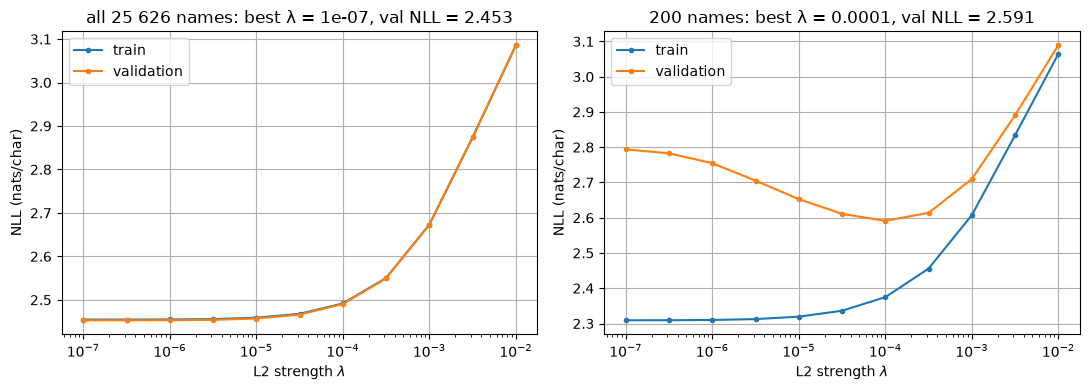

In [15]:
def sweep_lambda(xs, ys, lams, steps=3000):
    """Train the regularised softmax regression on pairs (xs, ys); train/val NLL per lambda."""
    counts = np.zeros((V, V)); np.add.at(counts, (xs, ys), 1)
    out = []
    for lam in lams:
        lr = min(50.0, 0.5 / lam)                       # keep GD stable for large lambda
        W, _ = train_bigram_gd(counts, lam, lr, steps, log_every=steps)
        P = softmax(W)
        out.append((nll(P, xs, ys), nll(P, x_va, y_va)))
    return np.array(out)

lams = np.logspace(-7, -2, 11)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (label, (xs, ys)) in zip(axes, {"all 25 626 names": (x_tr, y_tr), "200 names": (x_small, y_small)}.items()):
    r = sweep_lambda(xs, ys, lams)
    ax.semilogx(lams, r[:, 0], "o-", ms=3, label="train")
    ax.semilogx(lams, r[:, 1], "o-", ms=3, label="validation")
    ax.set_title(f"{label}: best λ = {lams[np.argmin(r[:, 1])]:.1g}, val NLL = {r[:, 1].min():.3f}")
    ax.set_xlabel(r"L2 strength $\lambda$"); ax.set_ylabel("NLL (nats/char)"); ax.legend()
plt.tight_layout(); plt.show()

The curves have the same shape as the add-$\alpha$ curves of Section 6: L2 on the logit
table *is* a smoothing method, and with little data it buys a sizeable improvement in
validation NLL. This is the first appearance of a theme that runs through the whole
course: regularisation (Lecture 5) is a way of encoding prior beliefs, and for language
models those beliefs are about how to spread probability over sequences we have
never seen.

## 10. Summary

| Concept | Formula / fact |
|---|---|
| Autoregressive LM | $p(x_{1:T}) = \prod_t p(x_t\mid x_{<t})$ |
| Bigram assumption | $p(x_t\mid x_{<t}) \approx p(x_t\mid x_{t-1})$ |
| MLE | $\hat p(j\mid i) = N_{ij}/\sum_k N_{ik}$ |
| NLL / perplexity | $-\frac1T\sum_t\log p(x_t\mid x_{<t})$; $\text{PPL} = e^{\text{NLL}}$; uniform: $\ln 27 \approx 3.30$ |
| Add-$\alpha$ smoothing | $(N_{ij}+\alpha)/(\sum_k N_{ik}+V\alpha)$ |
| Softmax regression view | one-hot input selects a row of the logit table $W$; optimum $=$ counts |
| L2 on $W$ | pulls rows towards uniform $\Rightarrow$ smoothing |

Our reference number for the rest of the track:

In [16]:
print(f"bigram (add-alpha, alpha = {alpha_best:.3g}) | softmax regression (GD, 3000 steps): "
      f"val NLL {nll_count_val:.4f} | {nll(P_gd, x_va, y_va):.4f}")
print(f"val NLL (nats/char): {nll_count_val:.3f}")

bigram (add-alpha, alpha = 0.316) | softmax regression (GD, 3000 steps): val NLL 2.4530 | 2.4529
val NLL (nats/char): 2.453


## From here to LLMs

* **Same objective.** A GPT model is trained by minimising exactly the NLL of Section 5 —
  mean cross-entropy of the next token — over trillions of tokens. Reported "loss"
  numbers in LLM papers are nats (sometimes bits) per token, and perplexity is still a
  standard evaluation metric.
* **Same output layer.** The last layer of every LLM is a softmax regression: a hidden
  vector $\mathbf h_t$ (instead of our one-hot $\mathbf x$) multiplied by an "unembedding"
  matrix $W\in\mathbb R^{d\times|\mathcal V|}$ gives the logits. Our $27\times27$ table is the
  degenerate case where $\mathbf h_t$ is a one-hot code of the previous character.
* **Same sampling loop.** Generation is the loop of Section 7: sample a token, append it,
  repeat until an end-of-sequence token. Temperature, top-$k$ and nucleus sampling only
  change how the distribution `P[ix]` is post-processed before drawing.
* **Tokenisation matters.** Production models use subword vocabularies of 32k–256k tokens
  (byte-pair encoding), a compromise between our 27 characters and the word vocabulary
  of Section 2. The NLL per *token* therefore depends on the tokeniser; compare models in
  bits per character or per byte when tokenisers differ.
* **Smoothing became regularisation and scale.** $n$-gram LMs relied on clever smoothing
  (Kneser–Ney); neural LMs never assign exactly zero probability because the softmax is
  always positive, and they generalise to unseen contexts through shared parameters —
  the subject of the next notebook.

## Try it yourself

1. Compute the bigram model's NLL in **bits** per character and its perplexity on the
   test split. How many bits would an ideal compressor need to store all test names?
2. Build a **trigram** count model ($27^2$ contexts). How many contexts are never seen in
   training? What smoothing $\alpha$ is best now, and does it beat the bigram on validation?
3. Add a **temperature** $\tau$ to the sampler: use $\operatorname{softmax}(W/\tau)$. What
   happens to the samples for $\tau = 0.5$ and $\tau = 2$?
4. Train the softmax regression with **mini-batch** SGD on the one-hot inputs (as in
   Lecture 1's `train_softmax`) instead of the count shortcut. How does the loss curve
   compare to full-batch GD at equal compute?
5. Find the value of $\lambda$ that best matches add-$\alpha$ smoothing with $\alpha = 1$ on the
   200-name subset, by comparing the learned and smoothed tables cell by cell.

**Further reading.**
Jurafsky & Martin, *Speech and Language Processing* (3rd ed. draft), ch. 3 "N-gram Language Models";
Shannon (1948), "A mathematical theory of communication" (§3 generates text from $n$-gram models);
Chen & Goodman (1999), "An empirical study of smoothing techniques for language modeling";
Andrej Karpathy, "The spelled-out intro to language modeling: building makemore" (video lecture, 2022).